# Batch integration of a cohort's scRNA with Harmony and scVI

We load a pregrown cohort of patients, measure their dissociated cells by single-cell RNA sequencing (scRNA-seq) in sequencing batches whose technical settings were fitted to a real atlas, and integrate the batches with Harmony ([Korsunsky et al. 2019](https://github.com/slowkow/harmonypy)) and scVI ([Lopez et al. 2018](https://scvi-tools.org)), both through scanpy.
We pool the same cells into batches in two designs, one batch per patient and patients spread across batches, and score each integration against the ground truth by how well it mixes the batches and by how much of the patient-specific clonal structure of the cancer cells it keeps.
[The cohort tutorial](04_cohort.ipynb) shows how a cohort is grown and what its ground truth holds.

Harmony and scVI run in their own conda environment, `iscc-integration` (scanpy, harmonypy and scvi-tools on CPU), from a short script that the notebook writes.

In [1]:
import os
import tempfile

import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.neighbors import NearestNeighbors

import iscc.pregrown
from iscc.cohort import clone_key, pool_cell_data, run_cohort_batches
from iscc.data import atlas_scrna_batches, concat_batches, run_scrna_batches, scRNA
from iscc.integrations import clones_from_clades
from iscc.sample import Resection

INTEGRATION_PYTHON = os.path.expanduser("~/miniconda3/envs/iscc-integration/bin/python")
os.chdir(tempfile.mkdtemp())        # the data and the tool's outputs go to a scratch directory

## A pregrown cohort of six patients

We load the pregrown cohort ([`iscc.pregrown.cohort`](https://pedrofale.github.io/iscc/reference/pregrown_cohort/)), six patients of the paper's regime with immune cells, each grown from its own seed to 60,000 cancer cells on a field of 96 by 96 demes.
As in any [`Cohort`](https://pedrofale.github.io/iscc/reference/Cohort/), the patients were grown over one gene layout, so they share their drivers, baseline expression and programs and differ in how their tumors evolved.

In [2]:
cohort = iscc.pregrown.cohort()

## Batches and dissociations that differ as real ones do

Real batches differ by their own technical settings, and the samples of different patients are dissociated separately.
As in the `iscc` paper, we give each batch the settings that the estimators of `iscc` ([`estimate_rna`](https://pedrofale.github.io/iscc/reference/estimate_rna/)) fitted to one tumor of the breast cancer atlas of Wu et al. (2021), in which each tumor was its own 10x run, and [`atlas_scrna_batches`](https://pedrofale.github.io/iscc/reference/atlas_scrna_batches/) draws them.
The mean and spread of the library size, the dispersion, the dropout and the doublet rate of a tumor come from its cells, and its dissociation stress from the expression of the dissociation-response genes of van den Brink et al. (2017) in its cells, relative to the median over the atlas.
The ambient fraction is drawn for each batch from the range measured in 10x data of dissociated tissue (Janssen et al. 2023), since the counts of most tumors do not identify it.
We draw six tumors and give the i-th to patient i and to batch i.

In [3]:
settings = atlas_scrna_batches(6, seed=0)          # one tumor of the atlas per batch and patient
batch_kwargs = settings.drop(columns="stress_strength").to_dict("records")
settings.round(3)

,mu_lib,sigma_lib,dispersion,dropout_mid,dropout_shape,doublet_rate,ambient_frac,stress_strength
tumor,,,,,,,,
CID45171,1960.200,0.336,0.213,0.0,0.860,0.019,0.031,0.000
CID4471,2525.180,0.439,0.155,0.0,0.711,0.066,0.095,0.091
CID4461,466.412,0.437,0.047,0.0,0.693,0.005,0.103,0.000
CID4040,5062.630,0.350,0.365,0.0,0.599,0.020,0.079,0.449
CID4066,1688.460,0.391,0.093,0.0,0.691,0.041,0.088,0.235
CID3838,6289.320,0.431,0.062,0.0,0.392,0.018,0.073,0.534


The mean library sizes fitted to the six tumors range from about 470 to 6,300 UMIs per cell, and four of the six patients have a dissociation stress.
We dissociate each resected tumor into 1,000 cells ([`Resection`](https://pedrofale.github.io/iscc/reference/Resection/)), of which each cell type is recovered with the default probability of the type, and multiply the expression of one set of stress genes, shared by every patient, by one plus the stress of the patient.
The stress genes are 5% of the genes, drawn at random.
A first dissociation of the same cells without stress gives the reference below.
We make the dissociated cells the tumor's own cell data (`install=True`), which the cohort's batching functions read.

In [4]:
def dissociate(stress, stress_genes=None):
    for patient, s in zip(cohort.patients, stress):
        specimen = Resection(patient.tumor)
        specimen.dissociate(specimen.cancer_region(margin=1), max_cells=1000, recovery_probs="default",
                            seed=patient.seed, install=True, stress_strength=s, stress_genes=stress_genes)
    return pool_cell_data(cohort.patients)


unstressed, meta = dissociate([0.0] * len(cohort.patients))
genes = unstressed["cell_exp"].columns
stress_genes = list(np.random.default_rng(0).choice(genes, size=round(0.05 * len(genes)), replace=False))
pooled, meta = dissociate(settings["stress_strength"], stress_genes)
pd.crosstab(meta["patient"], meta["cell_type"], margins=True)

cell_type,cancer,epithelial,immune,stromal,All
patient,,,,,
0,326,33,233,408,1000
1,313,23,247,417,1000
2,310,28,226,436,1000
3,294,31,261,414,1000
4,308,27,276,389,1000
5,354,35,173,438,1000
All,1905,177,1416,2502,6000


The ground truth holds the patient and the cell type of every cell, and the true genealogy of each tumor defines the clones.
We call a clone each clade of the genealogy that holds at least 20 of the patient's sampled cells ([`clones_from_clades`](https://pedrofale.github.io/iscc/reference/clones_from_clades/)), and name it with `clone_key` by the patient, since clone labels and genotype ids are unique only within a patient.

In [5]:
clones = pd.concat([clones_from_clades(p.tumor, min_cells=20).astype(str)
                    .rename(lambda c, p=p: f"P{p.patient_id}::{c}")     # the names of the pooled cells
                    for p in cohort.patients])
meta["lineage"] = [clone_key(p, c) for p, c in zip(meta["patient"], clones.reindex(meta.index))]
meta.loc[meta["cell_type"] == "cancer"].groupby("patient")["lineage"].nunique().rename("clones").to_frame().T

patient,0,1,2,3,4,5
clones,6,5,4,5,7,5


## Two pooling designs

We measure the cohort with the 10x Genomics preset of [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/) in six batches, each with the settings of its tumor above (`batch_kwargs`).
In the first design each patient is its own batch, as when patients are sequenced one at a time ([`run_cohort_batches`](https://pedrofale.github.io/iscc/reference/run_cohort_batches/)), so the batch and the patient are confounded.
In the second design the pooled cells are split at random into six batches, each holding every patient, as when patients are multiplexed ([`run_scrna_batches`](https://pedrofale.github.io/iscc/reference/run_scrna_batches/)), while each patient keeps its own dissociation stress.
The same cells measured in one batch without any batch effect or dissociation stress give the reference, the structure an integration should keep.

In [6]:
def to_h5ad(assays, name):
    for a in assays:                                   # the ground truth, for scoring only
        a.obs[["patient", "cell_type", "lineage"]] = meta.loc[a.obs.index, ["patient", "cell_type", "lineage"]].to_numpy()
    adata = concat_batches(assays)
    adata.obs = adata.obs.astype({"patient": str})
    adata.write_h5ad(f"{name}.h5ad")
    return adata


by_patient, _, _ = run_cohort_batches(cohort, mapping="one_to_one", n_cells_per_patient=None, protocol="10x",
                                      batch_kwargs=batch_kwargs)
across = run_scrna_batches(pooled, n_batches=6, design="split", n_cells=len(meta) // 6, protocol="10x",
                           batch_kwargs=batch_kwargs)
reference = scRNA(protocol="10x", n_cells=len(meta), sigma_batch=0.0, depth_batch_sigma=0.0, seed=7).run(unstressed)
data = {"by patient": to_h5ad(by_patient, "by_patient"), "across patients": to_h5ad(across, "across_patients"),
        "reference": to_h5ad([reference], "reference")}
for name, adata in data.items():
    umis = adata.obs.groupby("batch", observed=True)["n_counts"].median()
    print(f"{name:>15}: {adata.n_obs:,} cells in {adata.obs['batch'].nunique()} batches, "
          f"a median of {umis.min():,.0f} to {umis.max():,.0f} UMIs per cell")

     by patient: 6,000 cells in 6 batches, a median of 434 to 6,346 UMIs per cell
across patients: 6,000 cells in 6 batches, a median of 452 to 5,190 UMIs per cell
      reference: 6,000 cells in 1 batches, a median of 3,844 to 3,844 UMIs per cell


## Harmony and scVI

The script below runs the standard workflows of scanpy and scvi-tools on each data set.
It selects 2,000 highly variable genes on the counts across batches, normalizes and log-transforms them, and computes 50 principal components, which are the embedding without integration.
Harmony corrects the principal components for the batch (`sc.external.pp.harmony_integrate`), and scVI learns a latent space from the counts with the batch as a covariate, both at their defaults.
For each embedding, the script then builds the graph of the 15 nearest neighbors, computes the UMAP and draws it with `sc.pl.umap`, colored by the batch, the cell type and the patient of the cancer cells.

In [7]:
%%writefile integrate.py
import sys

import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import scvi

LABELS = {"none": "no integration", "Harmony": "Harmony", "scVI": "scVI"}
COLORS = {"batch": "batch", "cell_type": "cell type", "cancer_patient": "patient of the cancer cells"}


def main(name):
    adata = sc.read_h5ad(f"{name}.h5ad")
    adata.layers["counts"] = adata.X.copy()
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts",
                                batch_key="batch", subset=True)
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    sc.pp.pca(adata, n_comps=50)
    embeddings = {"none": "X_pca"}

    if adata.obs["batch"].nunique() > 1:
        sc.external.pp.harmony_integrate(adata, key="batch")
        embeddings["Harmony"] = "X_pca_harmony"

        scvi.settings.seed = 0
        scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="batch")
        model = scvi.model.SCVI(adata)
        model.train(accelerator="cpu", enable_progress_bar=False)
        adata.obsm["X_scVI"] = model.get_latent_representation()
        embeddings["scVI"] = "X_scVI"
        print(f"scvi-tools {scvi.__version__}: {name}, {model.history['elbo_train'].shape[0]} epochs")
    np.savez(f"{name}_embeddings.npz", obs_names=adata.obs_names.to_numpy(),
             **{method: adata.obsm[key] for method, key in embeddings.items()})

    adata.obs["cancer_patient"] = adata.obs["patient"].where(adata.obs["cell_type"] == "cancer")
    colors = [c for c in COLORS if c != "batch" or adata.obs["batch"].nunique() > 1]
    fig, axes = plt.subplots(len(embeddings), len(colors), figsize=(5.8 * len(colors), 4.4 * len(embeddings)),
                             squeeze=False, gridspec_kw={"wspace": 0.5})
    for row, (method, key) in zip(axes, embeddings.items()):
        sc.pp.neighbors(adata, use_rep=key)
        sc.tl.umap(adata)
        for ax, color in zip(row, colors):
            sc.pl.umap(adata, color=color, ax=ax, show=False, frameon=False,
                       title=f"{LABELS[method]}: {COLORS[color]}")
    fig.savefig(f"{name}_umap.png", dpi=72, bbox_inches="tight")


if __name__ == "__main__":
    main(sys.argv[1])

Writing integrate.py


In [8]:
for name in ["by_patient", "across_patients", "reference"]:
    !MPLBACKEND=Agg PYTHONWARNINGS=ignore {INTEGRATION_PYTHON} integrate.py {name} 2>> integrate.log

scvi-tools 1.4.2: by_patient, 400 epochs


scvi-tools 1.4.2: across_patients, 400 epochs


## UMAPs of the embeddings

The reference, measured in one batch without dissociation stress, shows the structure an integration should keep.
Its stromal cells form one cluster for each of their three subtypes, as do the immune cells, and the cancer cells form one cluster, within which the cells of each patient gather in a region of their own and the normal epithelial cells are scattered.
A few doublets form small clusters apart.

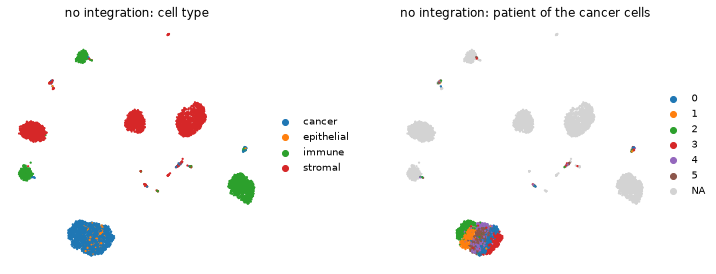

In [9]:
Image("reference_umap.png")

When each patient is its own batch, the stromal and immune cells without integration lie along their clusters in the order of their batches, and the cancer cells of different patients form separate clusters, since the batch effect adds to the differences between patients.
Harmony and scVI mix the stromal and immune cells of all batches, and they also mix the cancer cells of all patients into one cluster.

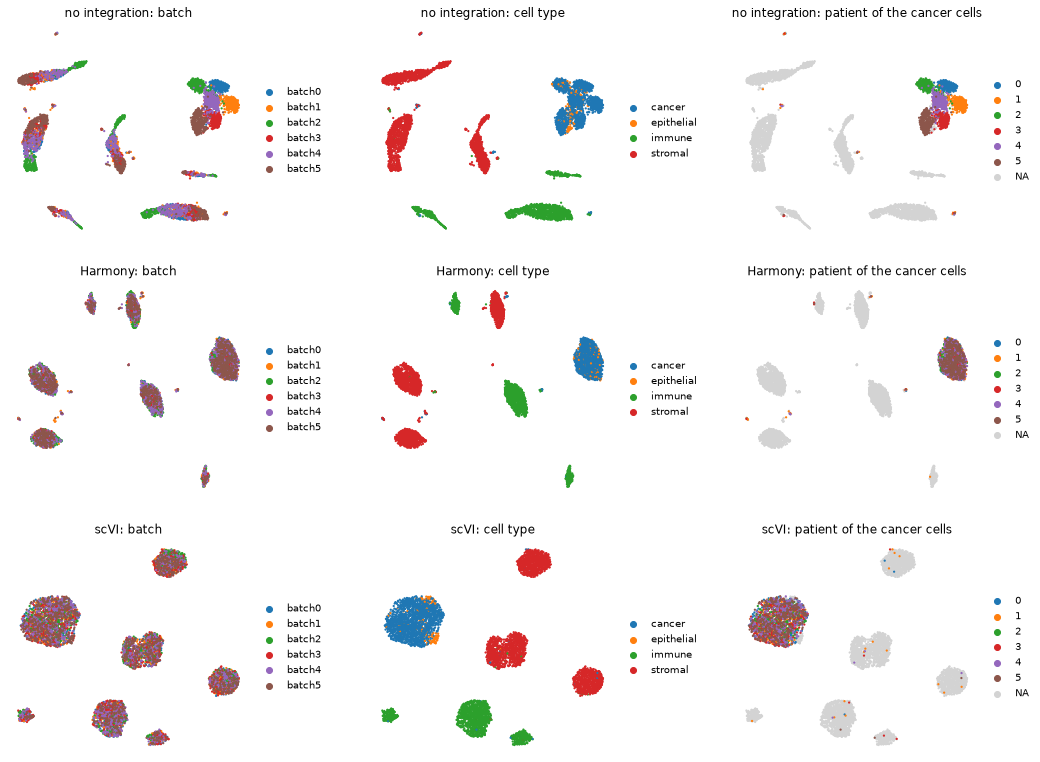

In [10]:
Image("by_patient_umap.png")

When the patients are spread across the batches, the cancer cells form one cluster without integration, in which the patients gather in partly separate regions, and the stromal and immune cells are again ordered by batch.
Harmony and scVI mix the batches among the stromal and immune cells, and keep the cancer cells of the patients in partly separate regions, scVI more clearly than Harmony.

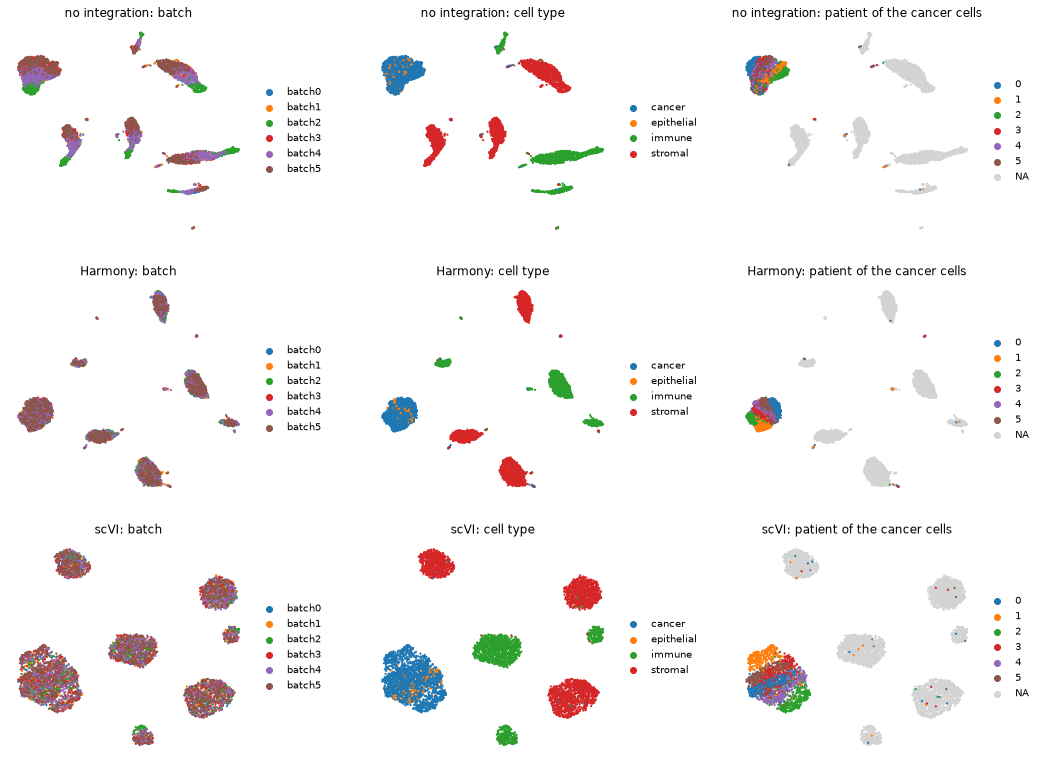

In [11]:
Image("across_patients_umap.png")

## Integration removes the differences between patients when each patient is its own batch

We score each embedding on the 30 nearest neighbors of each cell, through the share of neighbors that carry the same label as the cell.
Batch mixing is read on the microenvironment cells (immune, stromal and normal epithelial cells), which are biologically the same in every patient apart from the dissociation stress, so that an integration should mix them.
The share of neighbors from the same batch is 1/6 when the six batches are fully mixed and 1 when they are fully separated.
The patient-specific structure is read on the cancer cells, as the share of neighbors from the same patient, searched among the cancer cells, and the share from the same clone, searched among the cancer cells of the same patient.
The reference gives the values the biology sets, which an integration should keep.
We leave out the doublets, which are labeled as one of the two cells merged in them.

In [12]:
def same_label_share(embedding, labels, k=30):
    # mean share of the k nearest neighbors of each cell (itself excluded) that carry its label
    k = min(k, len(labels) - 1)
    neighbors = NearestNeighbors(n_neighbors=k).fit(embedding).kneighbors(return_distance=False)
    labels = np.asarray(labels)
    return (labels[neighbors] == labels[:, None]).mean()


rows = []
for name, adata in data.items():
    obs = adata.obs
    stored = np.load(f"{name.replace(' ', '_')}_embeddings.npz", allow_pickle=True)
    for method in [m for m in ("none", "Harmony", "scVI") if m in stored]:
        emb = pd.DataFrame(stored[method], index=stored["obs_names"]).loc[obs.index].to_numpy()
        single = ~obs["is_doublet"].to_numpy()
        micro = single & obs["cell_type"].isin(["immune", "stromal", "epithelial"]).to_numpy()
        cancer = single & (obs["cell_type"] == "cancer").to_numpy()
        clone_shares = [(same_label_share(emb[cancer & (obs["patient"] == p).to_numpy()],
                                          obs.loc[cancer & (obs["patient"] == p).to_numpy(), "lineage"]),
                         (cancer & (obs["patient"] == p).to_numpy()).sum()) for p in obs["patient"].unique()]
        rows.append({"design": name, "integration": method,
                     "own batch (microenvironment)": same_label_share(emb[micro], obs.loc[micro, "batch"])
                     if obs["batch"].nunique() > 1 else np.nan,
                     "own patient (cancer)": same_label_share(emb[cancer], obs.loc[cancer, "patient"]),
                     "own clone (cancer, within patient)": np.average([s for s, _ in clone_shares],
                                                                      weights=[n for _, n in clone_shares])})
scores = pd.DataFrame(rows).set_index(["design", "integration"]).round(2)
scores

own batch (microenvironment)  \
design          integration                                 
by patient      none                                 0.54   
                Harmony                              0.21   
                scVI                                 0.24   
across patients none                                 0.49   
                Harmony                              0.21   
                scVI                                 0.24   
reference       none                                  NaN   

                             own patient (cancer)  \
design          integration                         
by patient      none                         0.87   
                Harmony                      0.23   
                scVI                         0.22   
across patients none                         0.59   
                Harmony                      0.64   
                scVI                         0.72   
reference       none                         0.67   

                             own clone (cancer, within patient)  
design          integration                                      
by patient      none                                       0.32  
                Harmony                                    0.32  
                scVI                                       0.32  
across patients none                                       0.32  
                Harmony                                    0.33  
                scVI                                       0.32  
reference       none                                       0.32

Without integration, 0.54 and 0.49 of the neighbors of each microenvironment cell came from its own batch in the two designs, against 1/6 for full mixing.
Harmony and scVI brought this share to between 0.21 and 0.24 in both designs.
In the reference, 67% of the neighbors of each cancer cell came from the same patient.
The tumors of different patients carry different clones, but the 2,000 highly variable genes of the standard workflow, chosen over all cell types, capture only part of the differences between them: in a separate run on the reference, the share was 0.99 with the genes chosen on the cancer cells alone and 0.98 with 4,000 genes chosen on all cells.
When each patient was its own batch, Harmony and scVI cut this share to 0.23 and 0.22, close to the 1/6 of patients mixed at random, removing the differences between the tumors together with the batch effect, while without integration the batch effect added to them (0.87).
When the patients were spread across batches, the batch effect lowered this share to 0.59 without integration, and Harmony and scVI raised it to 0.64 and 0.72.
Within each patient, the share of neighbors from the same clone was 0.32 in the reference and 0.32 or 0.33 in every embedding, so the clonal structure within each tumor was kept in both designs.
Overall, the design decided whether integration kept the differences between patients, which the scores of batch mixing alone do not show.

## Making the benchmark harder or easier

The strength of the batch effect is set by the settings of each batch.
Here each batch took the settings fitted to one tumor of an atlas, and [`estimate_rna`](https://pedrofale.github.io/iscc/reference/estimate_rna/) fits them to the batches of any other data set.
Without `batch_kwargs`, every batch takes the 10x preset of [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/) and differs from the others only by its own draw of the batch effect, which separates the batches much less.
A larger per-gene factor (`sigma_batch`) or depth shift (`depth_batch_sigma`) separates the batches more, and a stronger dissociation stress (`stress_strength` of [`Resection.dissociate`](https://pedrofale.github.io/iscc/reference/Resection/)) separates the patients in both designs.
The design is the main lever.
Confounding batch with patient, as in the first design, asks an integration to tell technical from biological differences between patients, which the data alone can not settle.
The number of highly variable genes (`n_top_genes` in the script) sets how much of the differences between the cancer cells of different patients enters the embeddings.
More dissociated cells per patient give each patient more cancer cells and clones to score.
[The cohort tutorial](04_cohort.ipynb) shows how to grow a cohort of your own, with more patients or with a more unstable genome (`mutation_rate` and `wgd_rate` in the configuration, see [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/)), which in principle makes the patients, and the clones within each patient, differ more.